# Inference Problem Set

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns

# Problems 1-6

![PS Pic 1.jpeg](<attachment:PS Pic 1.jpeg>)
![PS Pic 2.jpeg](<attachment:PS Pic 2.jpeg>)
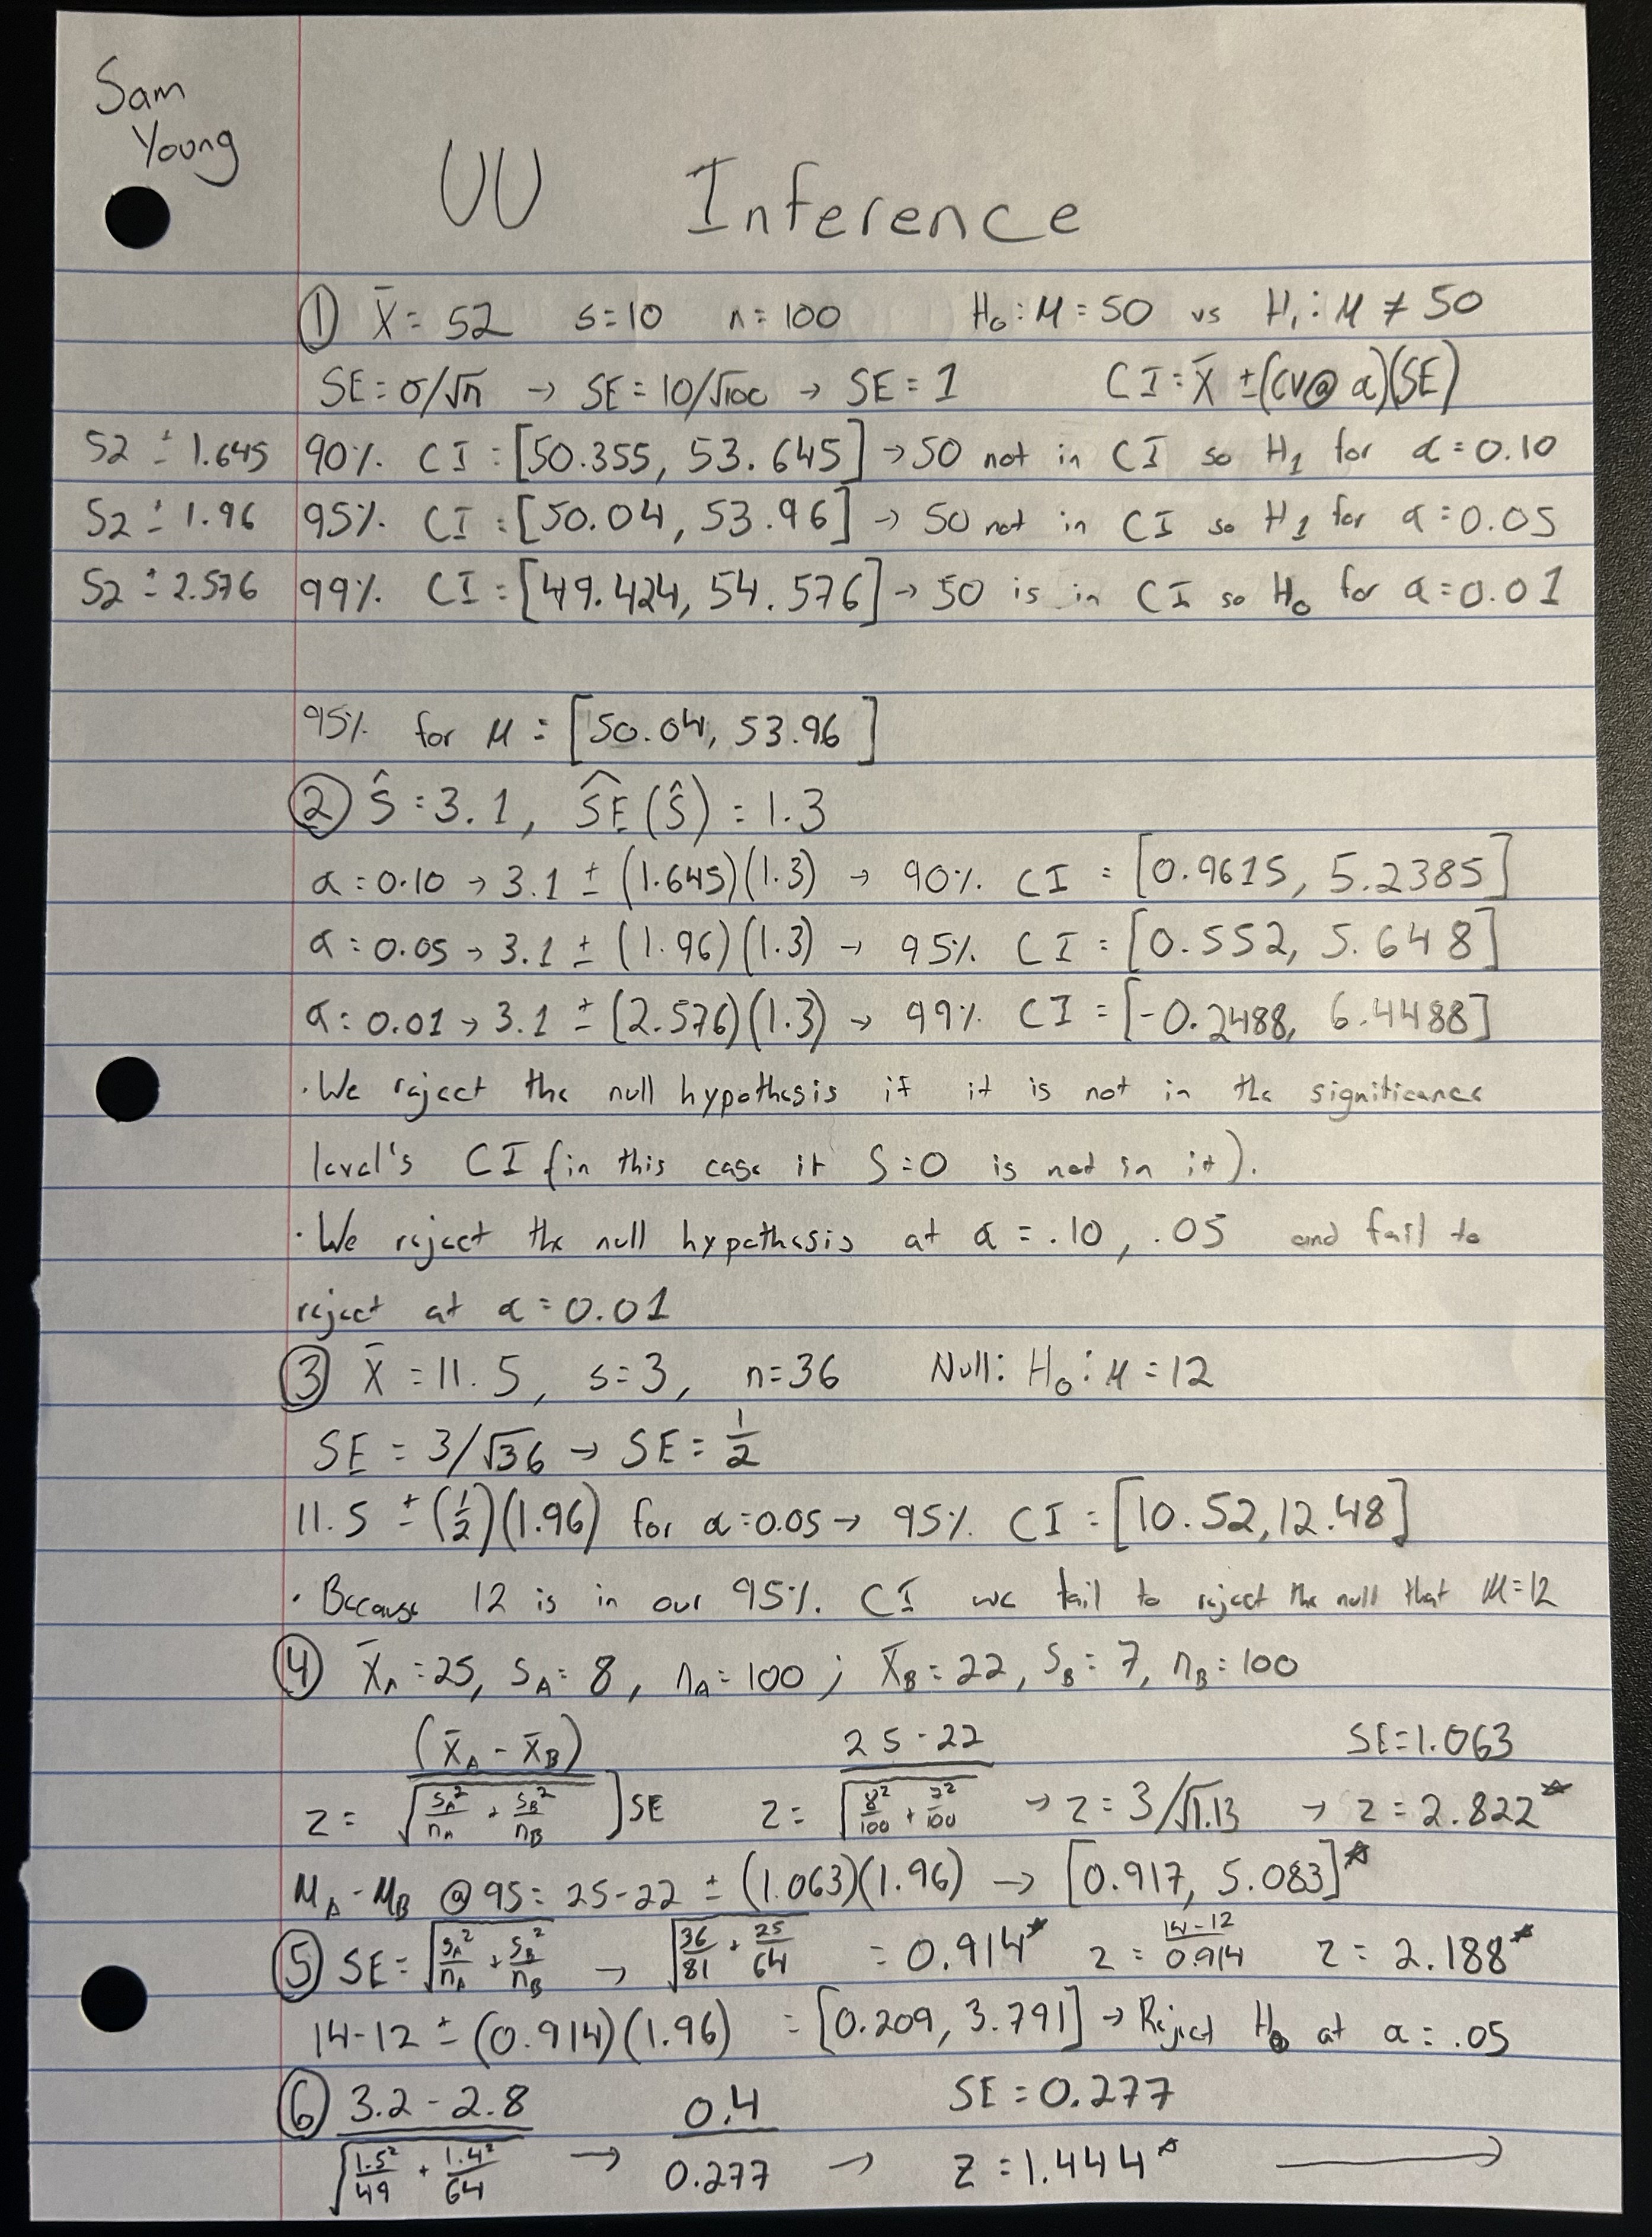
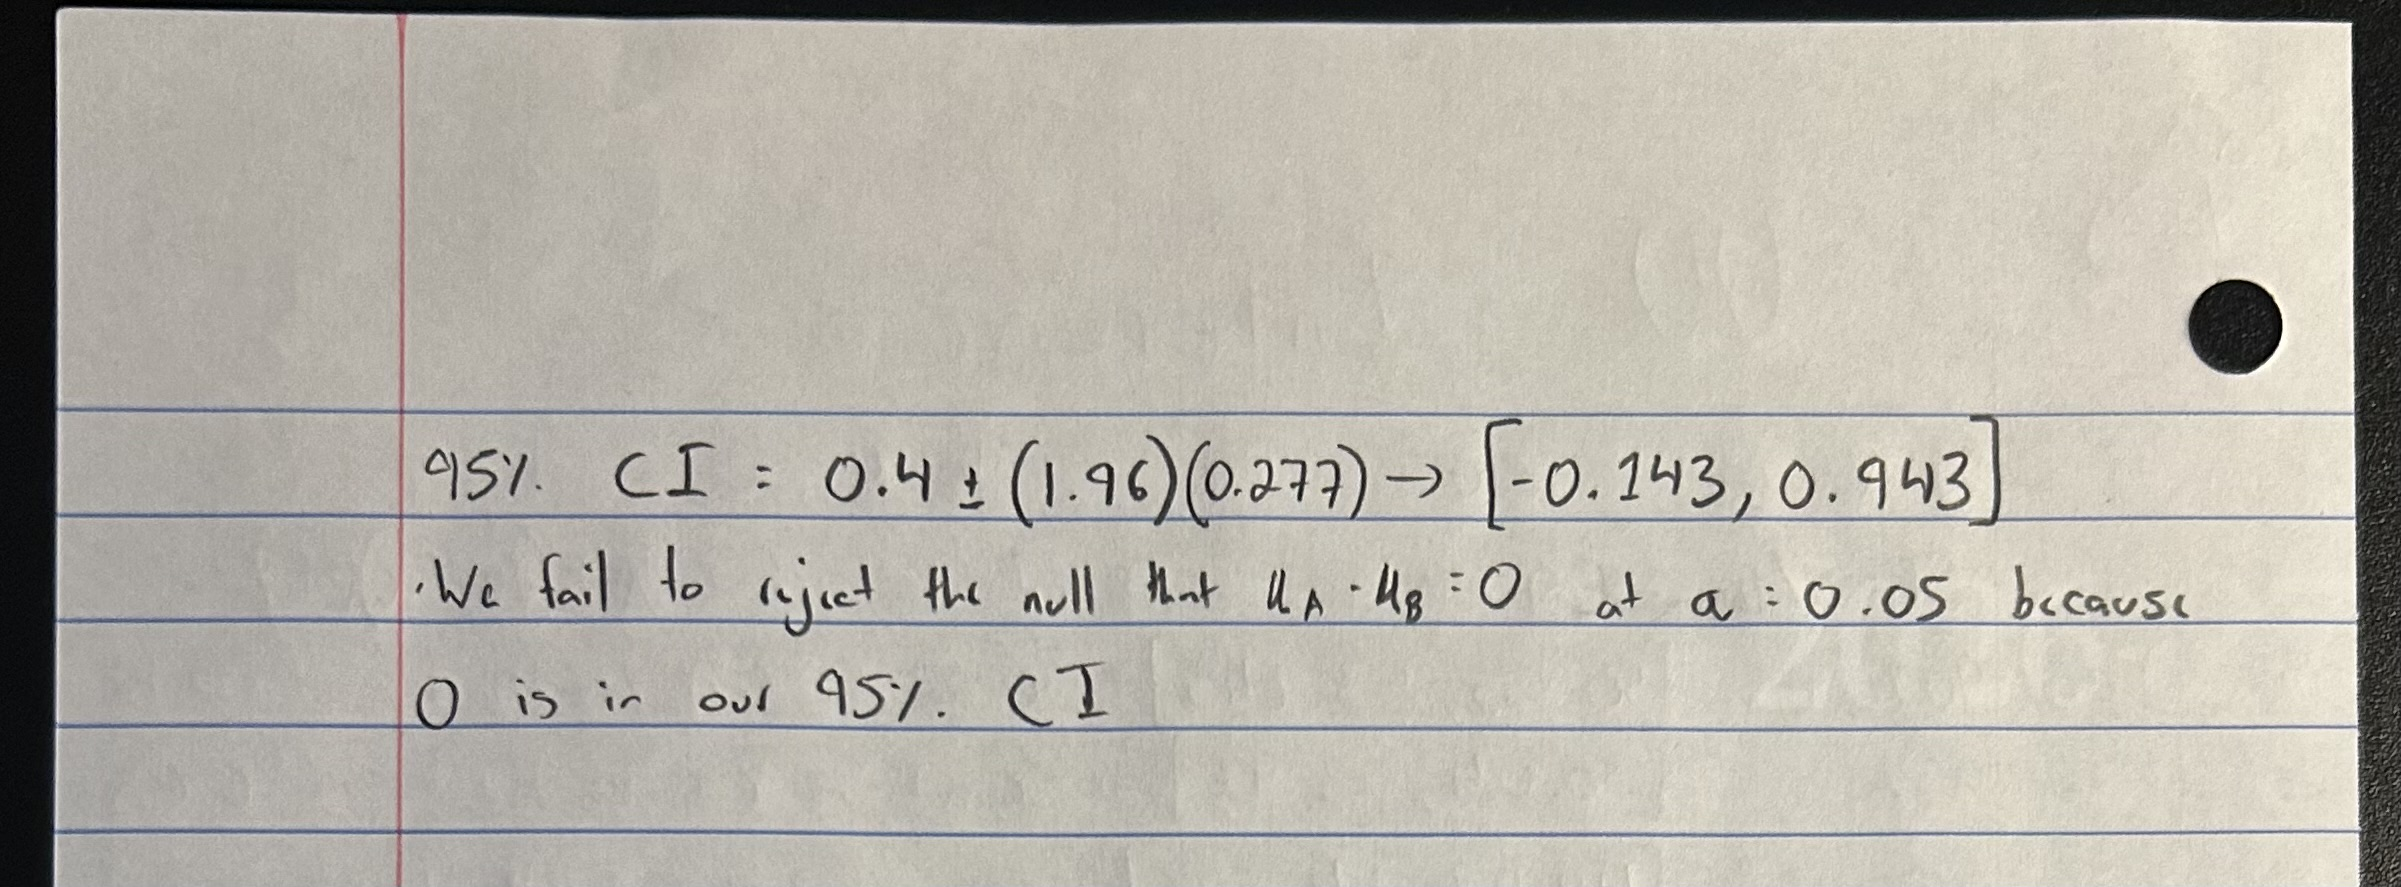

# Problem 7

In [3]:
ames_df = pd.read_csv('data/ames_prices.csv')

In [4]:
ames_df.head()

,Order,PID,area,price,MS.SubClass,MS.Zoning,Lot.Frontage,Lot.Area,Street,Alley,...,Screen.Porch,Pool.Area,Pool.QC,Fence,Misc.Feature,Misc.Val,Mo.Sold,Yr.Sold,Sale.Type,Sale.Condition
0,1,526301100,1656,215000,20,RL,141.0,31770,Pave,NaN,...,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal
1,2,526350040,896,105000,20,RH,80.0,11622,Pave,NaN,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
2,3,526351010,1329,172000,20,RL,81.0,14267,Pave,NaN,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
3,4,526353030,2110,244000,20,RL,93.0,11160,Pave,NaN,...,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal
4,5,527105010,1629,189900,60,RL,74.0,13830,Pave,NaN,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal


**a)**

In [5]:
ames_df['I.Central.Air'] = (ames_df['Central.Air'] == 'Y').astype(int)

In [40]:
ames_ca_mean = ames_df['I.Central.Air'].mean()
print(f'Central Air Proportion: {ames_ca_mean}')

Central Air Proportion: 0.9331058020477816


**b)**

In [7]:
rng = np.random.default_rng(seed=60)
R = 2_000
ca_means = []

for t in range(R):
    ca_bs = rng.choice(ames_df['I.Central.Air'], size=len(ames_df), replace=True)
    ca_mean = np.mean(ca_bs)
    ca_means.append(ca_mean)

ca_bs_avg = np.mean(ca_means)

print(f'Average bootstrap mean value: {ca_bs_avg} using {R} bootstrap samples and seed 60')

Average bootstrap mean value: 0.9330506825938567 using 2000 bootstrap samples and seed 60


**c)**

In [39]:
ca_se = np.std(ca_means, ddof=1)
print(f'Central Air Mean SE: {ca_se}')

Central Air Mean SE: 0.004557107216172265


**d)**

In [9]:
# Function to produce Normal CIs

def ci_creator(avg, se):
    ci_90 = np.append(avg - 1.645*se, avg + 1.645*se)
    ci_95 = np.append(avg - 1.96*se, avg + 1.96*se)
    ci_99 = np.append(avg - 2.576*se, avg + 2.576*se)

    print(f'90% CI: {ci_90}\n95% CI: {ci_95}\n99% CI: {ci_99}')

In [10]:
ci_creator(ames_ca_mean, ca_se)

90% CI: [0.92560936 0.94060224]
95% CI: [0.92417387 0.94203773]
99% CI: [0.92136669 0.94484491]


**e)**

- p = .90 does not fall within any of the confidence intervals at significance levels $\alpha$ = .10, .05 or .01. Therefore, we reject the null hypothesis at each significance level.

# Problem 8

In [11]:
ames_df['arcsinh_area'] = np.arcsinh(ames_df['area'])
ames_df['arcsinh_price'] = np.arcsinh(ames_df['price'])
correlation = ames_df['arcsinh_area'].corr(ames_df['arcsinh_price'])
print(f'Correlation: {correlation}')

Correlation: 0.7231661530091356


**a)**

In [12]:
rng = np.random.default_rng(seed=60)
R = 2_000
corr_values = []
n = len(ames_df)

for t in range(R):
    indices = rng.choice(n, size=n, replace=True)
    as_areas = ames_df['arcsinh_area'][indices]
    as_prices = ames_df['arcsinh_price'][indices]
    corr = as_areas.corr(as_prices)
    corr_values.append(corr)

avg_corr_values = np.mean(corr_values)

print(f'Average correlation value: {avg_corr_values} using {R} bootstrap samples and seed 60')

Average correlation value: 0.7230869884979306 using 2000 bootstrap samples and seed 60


**b)**

In [38]:
corr_se = np.std(corr_values, ddof=1)
print(f'Correlation SE: {corr_se}')

Correlation SE: 0.0099679802390391


**c)**

In [14]:
ci_creator(correlation, corr_se)

90% CI: [0.70676883 0.73956348]
95% CI: [0.70362891 0.74270339]
99% CI: [0.69748864 0.74884367]


**d)**

- p = 0 is in none of the above CIs, so we can reject the null hypothesis at every significance level

**e)**

- Both area and price should be sampled together so that there is continuity with the house data. We do not want to match one houses area with another's price. The correlation needs to look at both of these attributes for the same house and therefore, the two values should be bootstrapped together to maintain their relationship.

# Problem 9

**a)**

In [15]:
metabric_df = pd.read_csv('data/metabric.csv')

In [46]:
survival_mean = metabric_df['Overall Survival (Months)'].mean()
print(f'Survival Mean: {survival_mean}')

Survival Mean: 129.09429138744105


**b)**

In [53]:
rng = np.random.default_rng(seed=60)
R = 2_000
survival_means = []

for t in range(R):
    survival_bs = rng.choice(metabric_df['Overall Survival (Months)'], size=len(metabric_df), replace=True)
    survival_mean = np.mean(survival_bs)
    survival_means.append(survival_mean)

survival_bs_avg = np.mean(survival_means)

print(f'Average bootstrap mean value: {survival_bs_avg} using {R} bootstrap samples and seed 60')

Average bootstrap mean value: 129.29814070488956 using 2000 bootstrap samples and seed 60


**c)**

In [52]:
survival_se = np.std(survival_means, ddof=1)
print(f'Survival SE: {survival_se}')

Survival SE: 2.1438339448632378


**d)**

In [54]:
ci_creator(survival_mean, survival_se)

90% CI: [126.11000274 133.16321642]
95% CI: [125.43469505 133.83852411]
99% CI: [124.11409334 135.15912582]


- Reject the null hypothesis at every significance level since 120 is not in any of the CIs.

**e)**

In [45]:
ci_90_years = [125.56768455/12, 132.62089823/12]
ci_95_years = [124.89237686/12, 133.29620592/12]
ci_99_years = [123.57177515/12, 134.61680763/12]

print(f'90% CI: {ci_90_years}\n95% CI: {ci_95_years}\n99% CI: {ci_99_years}')

90% CI: [10.4639737125, 11.051741519166667]
95% CI: [10.407698071666667, 11.108017160000001]
99% CI: [10.297647929166667, 11.218067302500002]


- These values show us the confidence intervals for the mean "time to death" or "last follow up". Because this data includes both "time to death" and "last follow up", we cannot interpret it as just unrestricted mean lifetime (as those whose number is "last follow-up" live longer than the value recorded).

# Problem 10

In [22]:
sleep_df = pd.read_csv('data/nhanes_data_17_18.csv') #Load Data
sleep_df_18 = sleep_df[sleep_df['AgeInYearsAtScreening'] >= 18] #Only include respondents 18 or older 
sleep_df_18.dropna(subset=['SleepHoursWeekdaysOrWorkdays'], inplace=True) #Remove rows that have no sleep hour values

C:\Users\sjy3p\AppData\Local\Temp\ipykernel_1076\3058280808.py:1: DtypeWarning: Columns (0: ServedActiveDutyInUsArmedForces) have mixed types. Specify dtype option on import or set low_memory=False.
  sleep_df = pd.read_csv('data/nhanes_data_17_18.csv') #Load Data


In [55]:
sleep_mean = sleep_df_18['SleepHoursWeekdaysOrWorkdays'].mean()
print(f'Sleep Mean: {sleep_mean}')

Sleep Mean: 7.62124248496994


**a)**

In [58]:
rng = np.random.default_rng(seed=60)
R = 2_000
sleep_means = []

for t in range(R):
    sleep_bs = rng.choice(sleep_df_18['SleepHoursWeekdaysOrWorkdays'], size=len(sleep_df_18), replace=True)
    sleep_mean = np.mean(sleep_bs)
    sleep_means.append(sleep_mean)

sleep_bs_avg = np.mean(sleep_means)

print(f'Average bootstrap mean value: {sleep_bs_avg} using {R} bootstrap samples and seed 60')

Average bootstrap mean value: 7.620731098560758 using 2000 bootstrap samples and seed 60


**b)**

In [59]:
sleep_se = np.std(sleep_means, ddof=1)
print(f'Sleep Mean SE: {sleep_se}')

Sleep Mean SE: 0.022933948773972417


**c)**

In [60]:
ci_creator(sleep_mean, sleep_se)

90% CI: [7.61266535 7.68811804]
95% CI: [7.60544115 7.69534223]
99% CI: [7.59131384 7.70946954]


**d)**

- The null hypothesis is rejected at every significance level since 8 hours of sleep is in none of the above confidence intervals.

**e)**

- The practical significance of these findings differs from the statistical difference in that an average of 7.6 hours of sleep in reality is not too far off from 8 hours and may not have a significant real-life difference in affect. For practicality we must ask whether 7.6 hours of sleep has a similar enough effect compared to 8. However, statistically we absolutely reject that the mean is 8 hours as even the 99% CI is quite far off from including 8. 